In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
#data into train val

batch_size = 128
data_transform = transforms.Compose([
    transforms.ToTensor()
])

train_data = datasets.FashionMNIST(root = "./data", train = True, download= True, transform = data_transform)
train_loader = DataLoader(train_data, batch_size = batch_size, shuffle = True)



100%|██████████| 26.4M/26.4M [00:02<00:00, 11.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 165kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.05MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.5MB/s]


In [ ]:
# define auto encoder class

class AutoEncoder(nn.Module):
  def __init__(self, hidden_dim = 256, latent_dim = 64):
    super().__init__()

    # encoder
    self.encoder = nn.Sequential(
        nn.Linear(784, hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, latent_dim),
        nn.ReLU()
    )

    # decoder
    self.decoder = nn.Sequential(
        nn.Linear(latent_dim, hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, 784),
        nn.Sigmoid()
    )

  # forward pass
  def forward(self, x):
    z = self.encoder(x)
    x_reconstruction = self.decoder(z)

    return x_reconstruction

In [23]:
# defining the model , loss

model = AutoEncoder()
model.to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr = 1e-3)

In [24]:
# train the model

epochs = 10

model.train()

for epoch in range(epochs):
  total_loss = 0
  for x,_ in train_loader:
    x = x.view(-1, 784).to(device) # converting  [128,1,28,28] dimention to [128,784] dimention. here -1 is used to utilize the last batch efficiently. beacuse last batch may contain less data than 128. so to handle error -1 is used.

    optimizer.zero_grad()
    x_recon = model(x)
    loss = criterion(x_recon, x)
    loss.backward()
    optimizer.step()

    total_loss += loss

  avg_loss = total_loss/ len(train_loader)
  print(f"Epoch: [{epoch+1}/{epochs}], Loss: {avg_loss}")

Epoch: [1/10], Loss: 0.03346719965338707
Epoch: [2/10], Loss: 0.017440039664506912
Epoch: [3/10], Loss: 0.014821839518845081
Epoch: [4/10], Loss: 0.013281678780913353
Epoch: [5/10], Loss: 0.012275834567844868
Epoch: [6/10], Loss: 0.011558765545487404
Epoch: [7/10], Loss: 0.010937446728348732
Epoch: [8/10], Loss: 0.010488070547580719
Epoch: [9/10], Loss: 0.01006224099546671
Epoch: [10/10], Loss: 0.009734796360135078


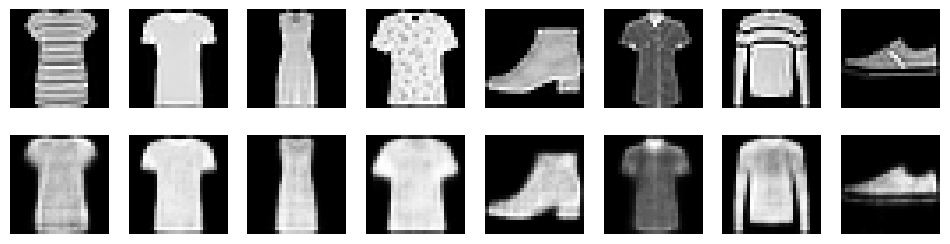

In [29]:
model.eval()

with torch.no_grad():
  x, _ = next(iter(train_loader))
  x = x.view(-1, 784).to(device)

  x_recon = model(x)

  n = 8

  plt.figure(figsize = (12,3))

  for i in range(n):
    plt.subplot(2, n, i+1)
    plt.imshow(x[i].cpu().view(28,28), cmap = "gray")
    plt.axis("off")

    plt.subplot(2,n, i+n+1)
    plt.imshow(x_recon[i].cpu().view(28,28), cmap = "gray")
    plt.axis("off")

  plt.show()